## Predict with e.g. 5 models, look at the variance
- hypothesis: 
    - for e.g. urban, it will be low 
    - for commodities, it will be low in areas with data and high in other 

In [1]:
import sys
import os
sys.path.append('../')


import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle
import pprint

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.geometry import box
from shapely.ops import nearest_points

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier
from utils import get_tiles_as_gdf

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

np.set_printoptions(suppress=True)


import matplotlib.colors as mcolors
import matplotlib.ticker as ticker
import cartopy.crs as ccrs
import cartopy.feature as cf
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


In [2]:
wandb_ids = [
    'roj0l5cx',
    'tdb1wbzo',
    'jp9ukkg4',
    'ljpkbdnc',
    'fuvmj0ci'
    
]
wandb_id = wandb_ids[0]




In [3]:
device = 'cuda'

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


#Load trained model
model = MultiModalDriverClassifier(11,  **config)
model = model.to(device)

trained_weights = f'../models_trained/{wandb_id}/last.pt'
_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
_ = model.eval()

# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [4]:
country_name_mapping = {
    "Vietnam" : "Viet Nam",
    "Tanzania" : "United Republic of Tanzania",
    "Dem. Rep. Congo" : "Democratic Republic of the Congo",
    "Dominican Rep." : "Dominican Republic",
    "Bolivia" : "Bolivia (Plurinational State of)",
    "Venezuela" : "Venezuela (Bolivarian Republic of)",
    "Central African Rep.": "Central African Republic",
    "Eq. Guinea" : "Equatorial Guinea",
    "eSwatini" : "Eswatini",
    "Laos" : "Lao People's Democratic Republic",
    "Taiwan" : "China, Taiwan Province of",
    "Brunei" : "Brunei Darussalam",
    "S. Sudan" : "South Sudan",
    "Solomon Is." : "Solomon Islands"
}

#Add country name
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

min_lon = -180
max_lon = 180
min_lat = -30
max_lat = 30
tropics = Polygon([(min_lon, min_lat), (min_lon, max_lat), (max_lon, max_lat, ), (max_lon, min_lat )])
tropical_countries = world.loc[world.intersects(tropics)]



/tmp/ipykernel_137659/590309720.py:19: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


In [5]:
forestloss_dir = '../../Vancutsem_yearloss'
tmf_extent = get_tiles_as_gdf(forestloss_dir)
tmf_extent.crs = 4326


# Load a land mask (for simplicity, this can be a GeoDataFrame of the world land mask)
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# Filter world data to only include land areas
land_areas = gpd.overlay(world, tmf_extent, how='intersection')

/tmp/ipykernel_137659/1446822280.py:7: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_137659/1446822280.py:9: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  land_areas = gpd.overlay(world, tmf_extent, how='intersection')


In [6]:
def find_intersections_or_nearest(gdf_points, gdf_polygons):
    """
    For each point in gdf_points, find which polygon it intersects with. 
    If it doesn't intersect any polygon, find the closest polygon.
    
    Parameters:
    gdf_points (GeoDataFrame): A GeoDataFrame containing points.
    gdf_polygons (GeoDataFrame): A GeoDataFrame containing polygons.
    
    Returns:
    GeoDataFrame: A GeoDataFrame of points with a new column 'nearest_or_intersecting_polygon' indicating the index of the intersecting or nearest polygon.
    """
    # Initialize a column to store the index of the nearest or intersecting polygon
    gdf_points['country'] = None
    
    for point_index, point_row in gdf_points.iterrows():
        # Check for intersections first
        intersects = gdf_polygons.intersects(point_row.geometry)
        if intersects.any():
            # If there's an intersection, use the first intersecting polygon
            idx = intersects.idxmax()
            gdf_points.at[point_index, 'country'] = gdf_polygons.iloc[idx]['name']
        else:
            # Find the nearest polygon if no intersection
            # Calculate the nearest points between the current point and all polygons, then find the minimum
            distances = gdf_polygons.geometry.apply(lambda poly: point_row.geometry.distance(nearest_points(point_row.geometry, poly)[1]))
            nearest_polygon_index = distances.idxmin()
            gdf_points.at[point_index, 'country'] = gdf_polygons.iloc[nearest_polygon_index]['name']
    
    return gdf_points

In [7]:
def add_country_names(gdf, country_name_mapping=country_name_mapping):

    gdf = gpd.sjoin(gdf, tropical_countries[['geometry', 'name']], how='left', predicate='within')[['geometry', 'driver', 'sampleid', 'dataset', 'name']]
    gdf['country'] = gdf['name']
    gdf = gdf.drop('name', axis=1)


    names_to_edit = [key for key in country_name_mapping.keys()]
    for name in names_to_edit:
        gdf.loc[gdf['country'] == name, 'country'] = country_name_mapping[name]

    return gdf

In [8]:

def generate_random_points_df(df, land_areas=land_areas, n_points=1000):

    # Create initial DataFrame with one row
    #df = pd.DataFrame(data)

    # Function to generate random points within the land mask
    def generate_random_point_within_land(land_areas):
        while True:
            # Generate random latitude and longitude within the tropics
            random_lat = random.uniform(-23.5, 23.5)
            random_lon = random.uniform(-180, 180)
            point = Point(random_lon, random_lat)


            # Check if point lies within land area
            for land_area in land_areas.geometry:
                if land_area.contains(point):
                    return point

    # Create a list of random points for 10,000 rows
    new_data = []
    for _ in tqdm.tqdm(range(n_points)):
        # Generate random land point
        random_point = generate_random_point_within_land(land_areas.geometry)
        row = df.iloc[0].copy()  # Copy the row template
        row['geometry'] = random_point  # Assign the new random point as geometry
        new_data.append(row)

    # Create a new DataFrame with 10,000 rows
    new_df = pd.DataFrame(new_data)
    new_df = new_df.reset_index(drop=True)

    return new_df


def predict(model, dataloader):
    
    model.eval()

    preds_batches = []
    targets_batches = []

    for data_batch, labels_batch in dataloader:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)
        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)
        
    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()

    preds = probabilities.argmax(dim=1).numpy()
    
    return probabilities.numpy(), preds

In [9]:
def write_annotation_file(sampleid, val_dl, out_path, points=1000):

    single_row_df = pd.DataFrame(val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.sampleid == sampleid])
    single_row_df = single_row_df.reset_index(drop=True)
    _df = generate_random_points_df(single_row_df,n_points=points)
    gdf = gpd.GeoDataFrame(_df)
    gdf.crs = 4326    
    gdf = add_country_names(gdf)
    gdf['split'] = 4
    pd.DataFrame(gdf).to_csv(f'../data/tmp/{out_file}.csv', index=False)
    gdf.to_file(f'../data/tmp/{out_file}.gpkg')


In [10]:
def load_model(wandb_id):
    model_dir = os.path.join('../models_trained', wandb_id)
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())


    #Load trained model
    model = MultiModalDriverClassifier(11,  **config)
    model = model.to(device)

    trained_weights = f'../models_trained/{wandb_id}/last.pt'
    _ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
    _ = model.eval()

    return model

## Palm oil

In [12]:
_sampleid = 90042955
out_file = 'palm_oil'

cls_index = 4

In [13]:
write_annotation_file(_sampleid, val_dl, out_file, 1000)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 148.88it/s]


In [14]:
config['data']['annotation_file'] = f'/home/jan/Documents/EPFL/project_2/data/tmp/{out_file}.csv'
# fetch dataloaders
cls_dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
cls_val_dl = cls_dataloaders['val']


gdf = gpd.read_file(f'../data/tmp/{out_file}.gpkg')



In [15]:

cls_probabilities = []
all_preds = []

for wandb_id in tqdm.tqdm(wandb_ids):
    
    model = load_model(wandb_id)
    probabilities, preds = predict(model, cls_val_dl)
    
    cls_probabilities.append(probabilities)
    all_preds.append(preds)
    
    
    
    
    
    
    
    
    

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:13<00:00,  2.74s/it]


In [16]:
all_probs = np.stack(cls_probabilities)
class_variances = np.var(all_probs, axis=0)
variance_measure = np.mean(class_variances, axis=1)

gdf['mean_variance'] = variance_measure 

all_preds = np.stack(all_preds)
ratio_of_correct_answers = (all_preds == cls_index).sum(axis=0)/5

gdf['correct_ratio'] = ratio_of_correct_answers 

## Plotting

In [17]:
#gdf = gdf.to_crs(3857)

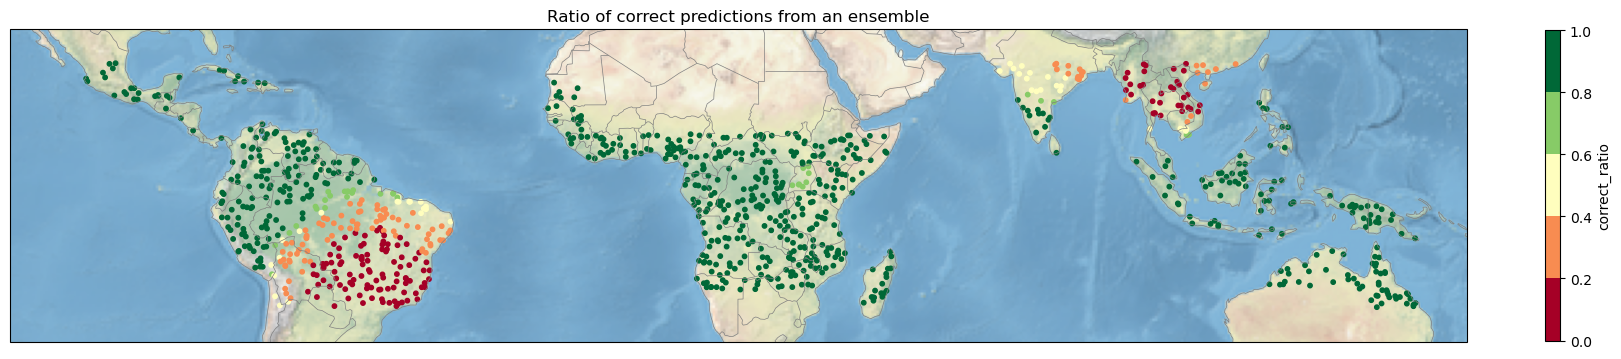

In [18]:


# Assuming 'gdf' is your GeoDataFrame and 'color_column' is your data column
color_column = 'correct_ratio'

# Reproject to PlateCarree projection (if needed)
gdf = gdf.to_crs(epsg=4326)

# Extract coordinates
lon = gdf.geometry.x
lat = gdf.geometry.y
colors = gdf[color_column]

# Set up the plot
proj = ccrs.PlateCarree()
fig = plt.figure(figsize=(20, 10))
ax = fig.add_subplot(111, projection=proj)

# Base map and features
ax.stock_img()
ax.add_feature(cf.COASTLINE, lw=0.5, edgecolor='gray')
ax.add_feature(cf.BORDERS, lw=0.5, edgecolor='gray')

# Define 5 sequential bins (adjust range based on your data)
num_bins = 5
#bins = ticker.MaxNLocator(nbins=num_bins).tick_values(colors.min(), colors.max())
bins = [0, 0.2, 0.4, 0.6, 0.8, 1]
#bins = [ 0.6, 0.8, 1]
norm = mcolors.BoundaryNorm(bins, ncolors=256)

# Plot points with discrete colormap
scatter = ax.scatter(lon, lat, c=colors, cmap='RdYlGn', s=10, transform=proj, norm=norm)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, orientation="vertical", pad=0.05, shrink=0.7, fraction=0.01)
cbar.set_label(color_column)

# Set map extent (adjust as needed)
ax.set_extent((-120, 160, -30, 30), crs=proj)
ax.set_title('Ratio of correct predictions from an ensemble')
# Show or save the plot
plt.show()

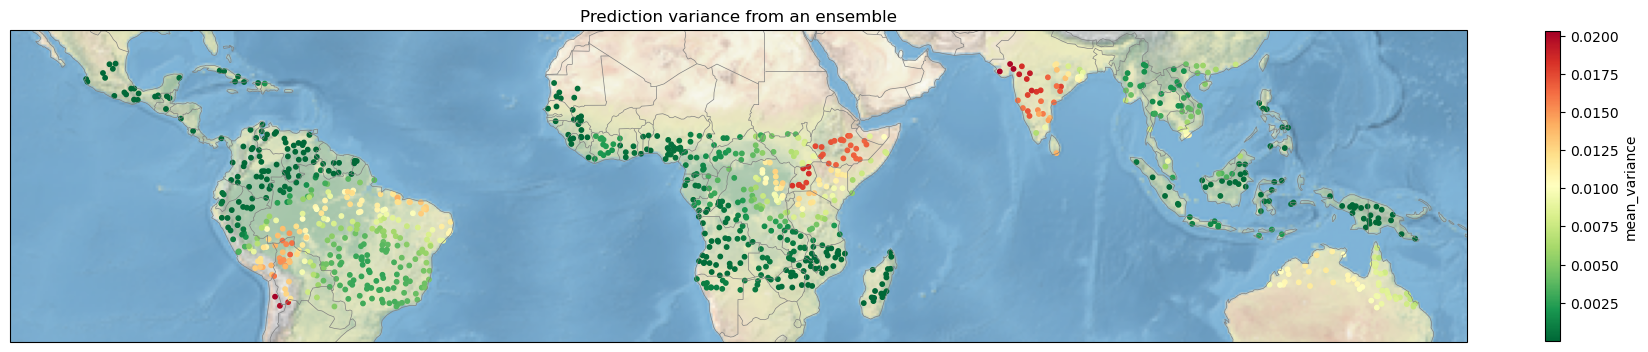

In [20]:

# Load or define your GeoDataFrame 'gdf'
# gdf = gpd.read_file(...) or similar
color_column = 'mean_variance'

# Ensure gdf is in the same projection as Cartopy's PlateCarree (EPSG:4326)
gdf = gdf.to_crs(epsg=4326)

# Extract coordinates
lon = gdf.geometry.x
lat = gdf.geometry.y
colors = gdf[color_column]

# Set up the plot
proj = ccrs.PlateCarree()
fig = plt.figure(figsize=(20, 10))
ax = fig.add_subplot(111, projection=proj)

# Base map and features
ax.stock_img()
ax.add_feature(cf.COASTLINE, lw=0.5, edgecolor='gray')
ax.add_feature(cf.BORDERS, lw=0.5, edgecolor='gray')

# Scatter plot for gdf points with color mapping
scatter = ax.scatter(lon, lat, c=colors, cmap='RdYlGn_r', s=10, transform=proj)

# Set map extent (adjust as needed)
ax.set_extent((-120, 160, -30, 30), crs=proj)

ax.set_title('Prediction variance from an ensemble')

# Add color bar
cbar = plt.colorbar(scatter, ax=ax, orientation="vertical", pad=0.05, shrink=0.7, fraction=0.01)
cbar.set_label(color_column)


# Show or save the plot
# plt.show()
# plt.savefig('output_plot.png', format='png', dpi=600, bbox_inches='tight')